# Jones pupils: polarization of the projection lens

A scalar pupil describes a projection lens by an amplitude (apodization)
and a phase (wavefront, Zernikes). At high NA the lens also changes the
**polarization** of the light: coatings and the Fresnel transmission of
every surface treat s and p differently, and the glass can be
birefringent (stress, or the intrinsic birefringence of CaF$_2$). The full
description is the **Jones pupil**: a $2\times 2$ complex matrix
$J(P_x, P_y)$ at every pupil point that maps the Jones vector of a ray
entering the lens to the one leaving it.

Eight real functions over the pupil are hard to read and hard to specify.
The literature uses these representations:

| representation | idea | reference |
|---|---|---|
| Jones–Zernike | each element $J_{jk}$ expanded into Zernikes | e.g. Totzeck et al. 2005 |
| Pauli–Zernike | $J = \sum_k a_k\sigma_k$, each $a_k$ expanded into Zernikes; $a_0$ is the scalar pupil, $a_1, a_2$ linear and $a_3$ circular retardance (imaginary parts) and diattenuation (real parts) | McIntyre, Kye, Levinson, Neureuther, JM3 5(3) 033001 (2006) |
| physical decomposition | polar decomposition $J = \sqrt{T}e^{i\Phi}\,U H$: transmission, phase, retarder $U$, diattenuator $H$ | Totzeck, Gräupner, Heil et al., JM3 4(3) 031108 (2005); Geh et al. |
| orientation Zernike polynomials (OZP) | retardance and diattenuation are *orientation fields* (an axis, defined modulo 180°), expanded into vector polynomials with Zernike radial parts | Ruoff, Totzeck, JM3 8(3) 031404 (2009); US patent 8,126,669 |

McIntyre et al. found the Pauli form the most useful for lithographers: its
coefficients separate the physical effects and are linear in small
perturbations. The OZPs go one step further for retardance and
diattenuation: like scalar Zernikes they sort the orientation fields by
symmetry, so a rotationally symmetric radial retardance (typical for
coatings and mount stress) is a single term, and they are used to specify
and tolerance lenses through linear and quadratic sensitivities of CD and
placement.

`pyoptics.litho.jones_pupil` implements these bases in a modular way:

- `pauli_matrix`, `pauli_coefficients`: the Pauli algebra,
- `orientation_zernike(±j, P_x, P_y)`: OZPs as complex orientators
  $o_1 + i o_2 = |o|e^{2i\psi}$,
- `PauliZernikePupil`, `PhysicalJonesPupil` (retardance and diattenuation in
  OZPs, circular parts in Zernikes), both with `.fit()` to sampled Jones
  matrices,
- `compose`/`decompose`: the polar decomposition.

Any callable `J(P_x, P_y)` can be passed as `Projector(jones_pupil=...)`.
It acts on the Jones vector of every diffraction order before the aplanatic
rotation into image space, in Abbe and in Hopkins (`hopkins.TCC`) imaging.
`lens.lens_jones_pupil()` computes the Jones pupil of a ray traced lens by
polarization ray tracing (Chipman's $3\times 3$ matrices, Fresnel
coefficients of each surface, optional thin film coatings).

Contents:

1. Orientation Zernike polynomials.
2. Polarization ray trace of the Caldwell lens: uncoated and with an
   antireflection coating.
3. The same Jones pupil in the Pauli–Zernike and OZP bases.
4. Imaging with the lens Jones pupil.
5. OZP sensitivities of CD at NA 1.35: what a lens specification needs.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from pyoptics.litho import Illumination, LithoSimulation, MaskLayout, Projector, ThinMask, lens
from pyoptics.litho import jones_pupil as jp
from pyoptics.litho.plot import plot_orientation
from pyoptics.raytrace import caldwell_krf_lens

plt.rcParams.update({"figure.dpi": 100, "font.size": 11})

## 1. Orientation Zernike polynomials

An orientation $\psi$ (the fast axis of a retarder, the axis of best
transmission of a diattenuator) is defined modulo 180°. It is described by
the **orientator** $o = |o|\,e^{2i\psi}$, a 2-vector that turns twice as fast
as the axis. OZPs are a complete basis of orientator fields: the Zernike
radial polynomials $R_n^{|m|}(\rho)$ times $e^{\pm i m\phi}$, real and
imaginary (two OZPs per Zernike). Here they are labelled $\pm j$ with the
Fringe index $j$ such that the first component of OZ $+j$ is $Z_j$, as in
the patent; OZ $-j$ flips the sign of the second component. Examples:

- OZ $\pm 1$: constant orientation along x/y and along ±45°,
- OZ $\pm 2$, $\pm 3$: tilt-like, linear in $\rho$,
- OZ $+5 = \rho^2 e^{2i\phi}$: **radial** orientation (tangential for a
  negative coefficient), OZ $-6$: the same rotated by 45°, a spiral; both
  are rotationally symmetric,
- OZ $+4$, $+9$: x/y orientation with defocus- and spherical-like radial
  dependence.

The plots show the magnitude (color) and the orientation (ticks).

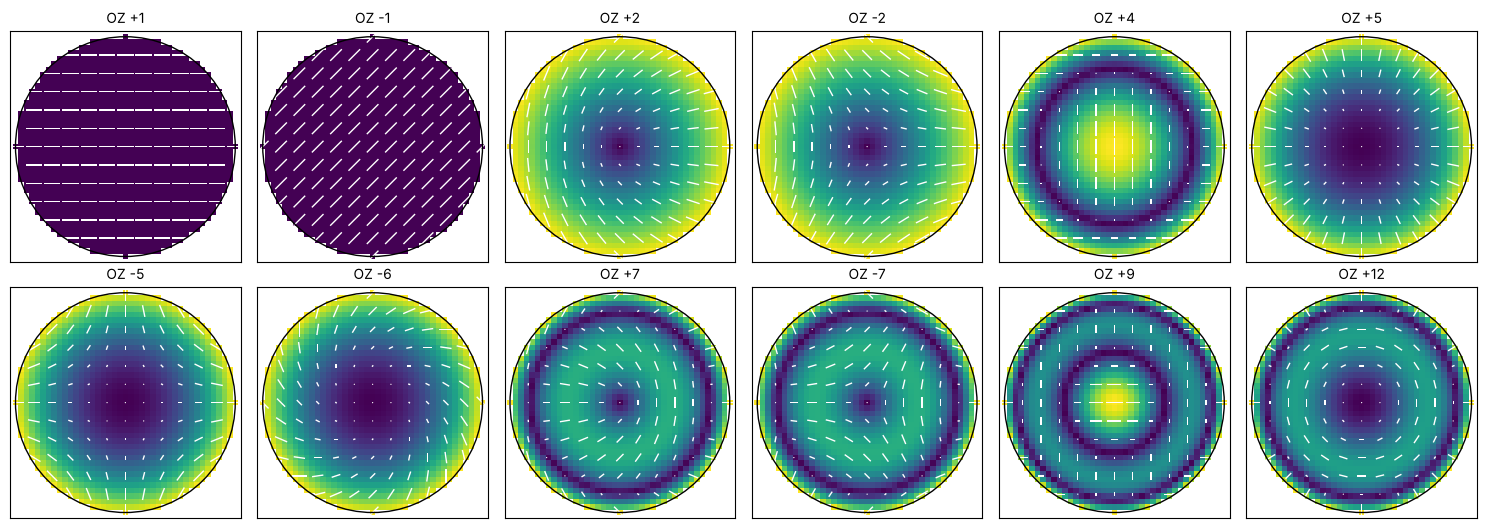

In [2]:
terms = [1, -1, 2, -2, 4, 5, -5, -6, 7, -7, 9, 12]
fig, axes = plt.subplots(2, 6, figsize=(15, 5.4))
for ax, oz in zip(axes.ravel(), terms):
    plot_orientation(lambda P_x, P_y: jp.orientation_zernike(oz, P_x, P_y), ax=ax,
                     title="OZ {:+d}".format(oz), colorbar=False)
plt.tight_layout()

Under a rotation of the lens by $\alpha$ an orientator rotates by $2\alpha$,
so the term $e^{im\phi}$ picks up $e^{i(2-m)\alpha}$. Only $m = 2$
($+5$, $-6$, $+12$, $-13$, ...) is rotationally symmetric. This is why a
rotationally symmetric lens has a Jones pupil of OZ $+5, +12, +21, \dots$
(radial/tangential) and $-6, -13, \dots$ (spiral) only, just as its
wavefront has only $Z_4, Z_9, \dots$.

## 2. Polarization ray trace of the Caldwell lens

`lens_jones_pupil()` traces rays through the pupil of the all fused silica
KrF lens (NA 0.56, 42 surfaces). At every surface it builds Chipman's
polarization ray tracing matrix

$$P = t_s\,\hat s\hat s^T + t_p\,\hat p'\hat p^T + \hat k'\hat k^T,$$

with the Fresnel amplitude transmissions $t_s$, $t_p$ (scaled such that
$|P\vec E|^2$ is the transmitted power) and multiplies them. The Jones pupil
is the product between the aplanatic bases of the object and the image
space ray (the identity for an ideal lens). It is normalized to the chief
ray, which leaves the dose unchanged.

Two cases: uncoated (every surface reflects about 4 % at normal incidence),
and every surface with an ideal single-layer quarter-wave antireflection
coating ($n_c = \sqrt{n_\mathrm{glass}}$).

In [3]:
system = caldwell_krf_lens()
n_glass = system.n[1]
coating = lens.quarter_wave_coating(n_glass, system.wavelength)
print("fused silica n = {:.4f}, coating n = {:.4f}, thickness {:.1f} nm".format(
    n_glass, coating[0][0], coating[0][1]*1e6))

uncoated = lens.lens_jones_pupil(system, N=41)
coated = lens.lens_jones_pupil(system, N=41, coating=coating)
for name, r in (("uncoated", uncoated), ("coated", coated)):
    print("{:9s}: chief ray transmission {:.3f}, {} rays, NA {:.3f}".format(
        name, r.transmission, len(r.P_x), r.NA))

fused silica n = 1.5084, coating n = 1.2282, thickness 50.5 nm


uncoated : chief ray transmission 0.172, 1257 rays, NA 0.560
coated   : chief ray transmission 1.000, 1257 rays, NA 0.560


`decompose()` splits every Jones matrix into the scalar transmission $T$ and
phase $\Phi$, the linear diattenuation $d$ (orientator, magnitude
$(T_\max - T_\min)/(T_\max + T_\min)$) and the linear retardance (orientator,
in waves).

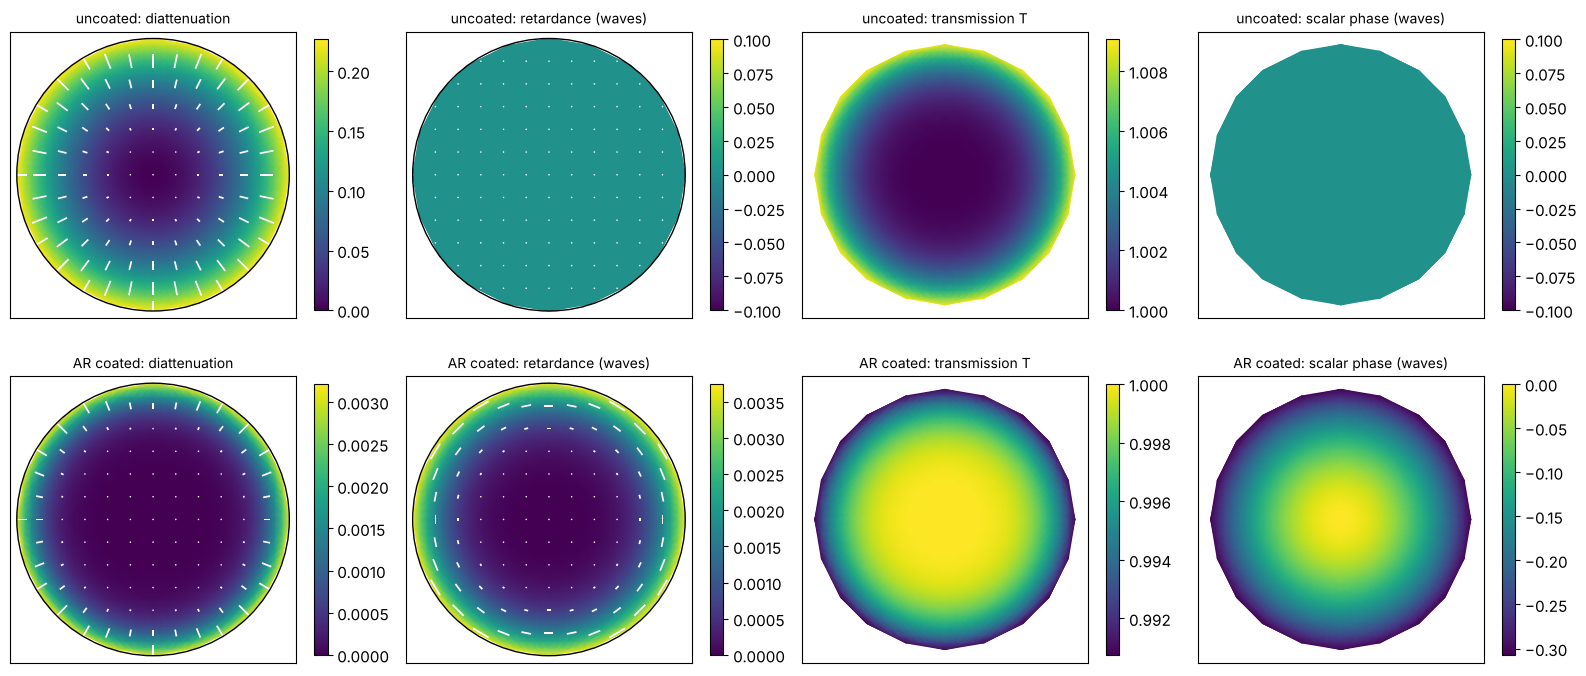

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7.2))
for row, (name, r) in zip(axes, (("uncoated", uncoated), ("AR coated", coated))):
    parts = jp.decompose(r.J)
    d, g = parts["diattenuation"], parts["retardance"]
    plot_orientation((r.P_x, r.P_y, d[0] + 1j*d[1]), ax=row[0], title=name + ": diattenuation")
    plot_orientation((r.P_x, r.P_y, g[0] + 1j*g[1]), ax=row[1],
                     title=name + ": retardance (waves)")
    for ax, v, title in ((row[2], parts["transmission"], "transmission T"),
                         (row[3], parts["phase"]/(2*np.pi), "scalar phase (waves)")):
        im = ax.tripcolor(r.P_x, r.P_y, v, shading="gouraud", cmap="viridis")
        ax.set_aspect("equal"), ax.set_xticks([]), ax.set_yticks([])
        ax.set_title(name + ": " + title, fontsize=10)
        plt.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()

The **uncoated** lens is a pure radial diattenuator: $p$ is transmitted
better than $s$ at oblique incidence (Brewster), and 42 surfaces add up to
a strong effect at the rim of the pupil. The Fresnel coefficients are real,
so there is no retardance. The **coating** removes most of the
diattenuation but adds retardance, because the phase of the transmission of
a thin film differs for s and p at oblique incidence. It also adds a
rotationally symmetric scalar phase, a wavefront error that the lens
designer has to include in the optimization.

## 3. The Jones pupil in the Pauli–Zernike and OZP bases

`PauliZernikePupil.fit()` expands the four Pauli coefficients into
Zernikes, `PhysicalJonesPupil.fit()` the decomposition: OZPs for linear
retardance and diattenuation, Zernikes for the circular parts and for the
scalar transmission and phase (returned separately, since these belong to
the Projector's apodization and Zernikes).

In [5]:
def large(coefficients, tol=1e-4):
    return {k: round(v, 4) for k, v in coefficients.items() if abs(v) > tol}

fits = {}
for name, r in (("uncoated", uncoated), ("coated", coated)):
    physical, scalar = jp.PhysicalJonesPupil.fit(r.P_x, r.P_y, r.J, n_terms=25)
    pauli = jp.PauliZernikePupil.fit(r.P_x, r.P_y, r.J, n_terms=36)
    fits[name] = physical, scalar, pauli
    print(name)
    print("  diattenuation OZP:  ", large(physical.diattenuation))
    print("  retardance OZP:     ", large(physical.retardance))
    print("  circular retardance:", large(physical.circular_retardance))
    print("  scalar phase:       ", large(scalar["phase"]))
    print("  transmission:       ", large(scalar["transmission"]))
    print("  fit errors |J_fit - J|: physical {:.1e}, Pauli-Zernike {:.1e}".format(
        np.abs(jp.compose(*physical.fields(r.P_x, r.P_y)) - jp.scalar_free(r.J)).max(),
        np.abs(pauli(r.P_x, r.P_y) - r.J).max()))

uncoated
  diattenuation OZP:   {5: 0.2182, 12: 0.0084, 21: 0.0002}
  retardance OZP:      {}
  circular retardance: {}
  scalar phase:        {}
  transmission:        {1: 1.0029, 4: 0.0045, 9: 0.0016}
  fit errors |J_fit - J|: physical 1.1e-06, Pauli-Zernike 6.6e-07
coated
  diattenuation OZP:   {5: 0.0018, 12: 0.0011, 21: 0.0003}
  retardance OZP:      {5: -0.0027, 12: -0.001}
  circular retardance: {}
  scalar phase:        {1: -0.1505, 4: -0.1535, 9: -0.0031, 16: -0.0001}
  transmission:        {1: 0.9971, 4: -0.0045, 9: -0.0017, 16: -0.0001}
  fit errors |J_fit - J|: physical 2.3e-05, Pauli-Zernike 1.5e-04


A handful of rotationally symmetric terms (OZ $+5$, $+12$, $+21$) describe
the polarization of the centred lens. In the Pauli basis the same
information is spread over $a_1$ and $a_2$, each with many Zernike terms:

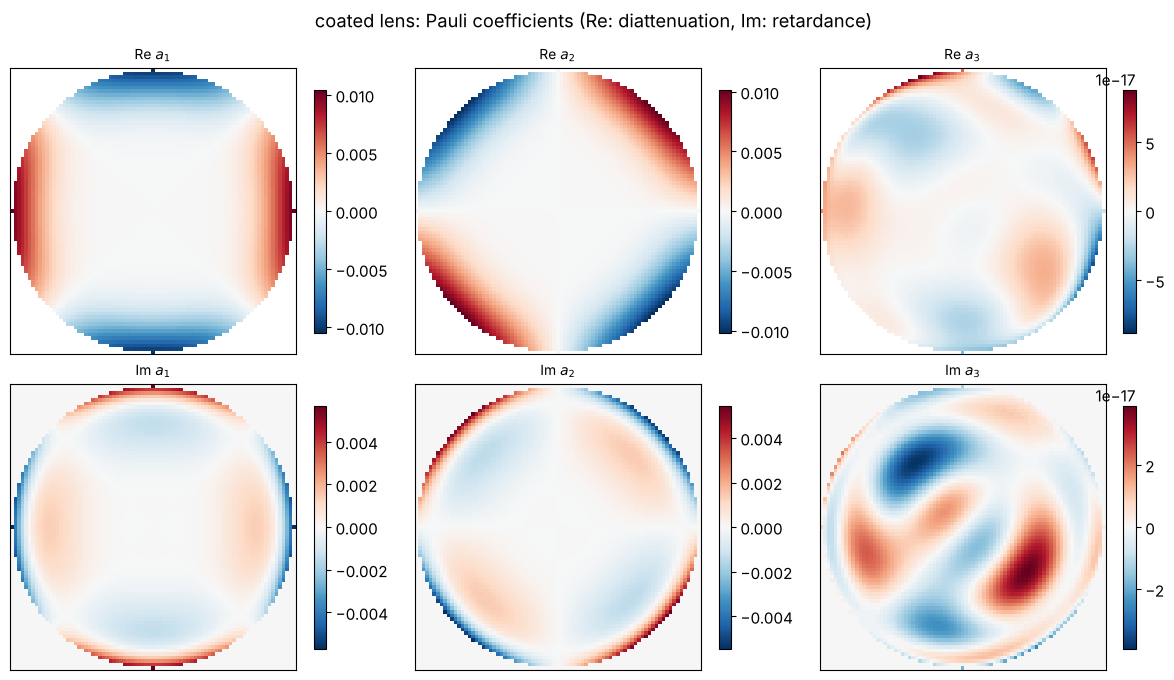

In [6]:
physical, scalar, pauli = fits["coated"]
P = np.linspace(-1, 1, 81)
PX, PY = np.meshgrid(P, P)
a = pauli.pauli(PX, PY)
a = np.where(PX**2 + PY**2 <= 1, a, np.nan)
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for k in range(1, 4):
    for row, (part, f) in enumerate((("Re", np.real), ("Im", np.imag))):
        ax = axes[row, k - 1]
        v = f(a[k])
        lim = np.nanmax(np.abs(v)) or 1
        im = ax.pcolormesh(P, P, v, cmap="RdBu_r", vmin=-lim, vmax=lim, shading="auto")
        ax.set_aspect("equal"), ax.set_xticks([]), ax.set_yticks([])
        ax.set_title("{} $a_{}$".format(part, k), fontsize=10)
        plt.colorbar(im, ax=ax, shrink=0.8)
fig.suptitle("coated lens: Pauli coefficients (Re: diattenuation, Im: retardance)")
plt.tight_layout()

For a rotationally symmetric lens, $a_1 \propto \cos 2\phi$ and
$a_2 \propto \sin 2\phi$ (astigmatism-like Zernikes $Z_5, Z_6, Z_{12},
Z_{13}, \dots$); the OZP basis collects both into one term per radial order.

### Through the field

Off axis the chief ray crosses the lens surfaces obliquely. Constant
(OZ $\pm1$) and tilt-like (OZ $\pm2$, $\pm3$) terms appear, and they grow
with the field, much like distortion and coma in the wavefront:

(<matplotlib.legend.Legend at 0x7fab240fd160>, None)

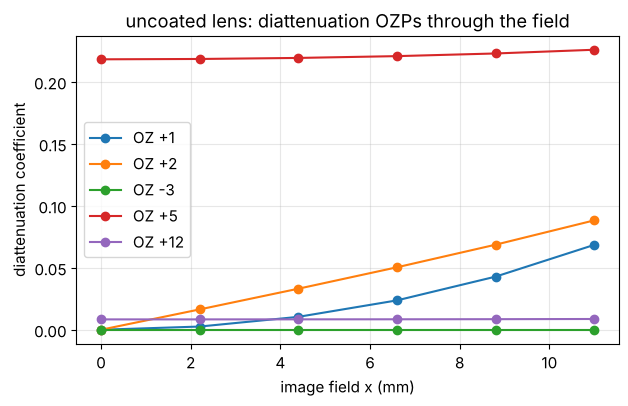

In [7]:
field_x = np.linspace(0, 11, 6)
rows = []
for x in field_x:
    r = lens.lens_jones_pupil(system, field=(x, 0.0), N=25)
    f, _ = jp.PhysicalJonesPupil.fit(r.P_x, r.P_y, r.J, n_terms=16)
    rows.append(f.diattenuation)
fig, ax = plt.subplots(figsize=(7, 4))
for oz in (1, 2, -3, 5, 12):
    ax.plot(field_x, [row[oz] for row in rows], "o-", label="OZ {:+d}".format(oz))
ax.set_xlabel("image field x (mm)"), ax.set_ylabel("diattenuation coefficient")
ax.set_title("uncoated lens: diattenuation OZPs through the field")
ax.legend(), ax.grid(alpha=0.3)

## 4. Imaging with the lens Jones pupil

`Projector(jones_pupil=...)` takes any of the fitted pupils. For the
Caldwell lens (KrF, dry, NA 0.56) we compare the CD of dense lines through
pitch with an annular source, polarized along x (TM for these vertical
lines), along y (TE) and unpolarized. For the coated lens we use the
polarization part only (`PhysicalJonesPupil`, without its scalar phase) and
the full Jones pupil, which includes the coating's wavefront.

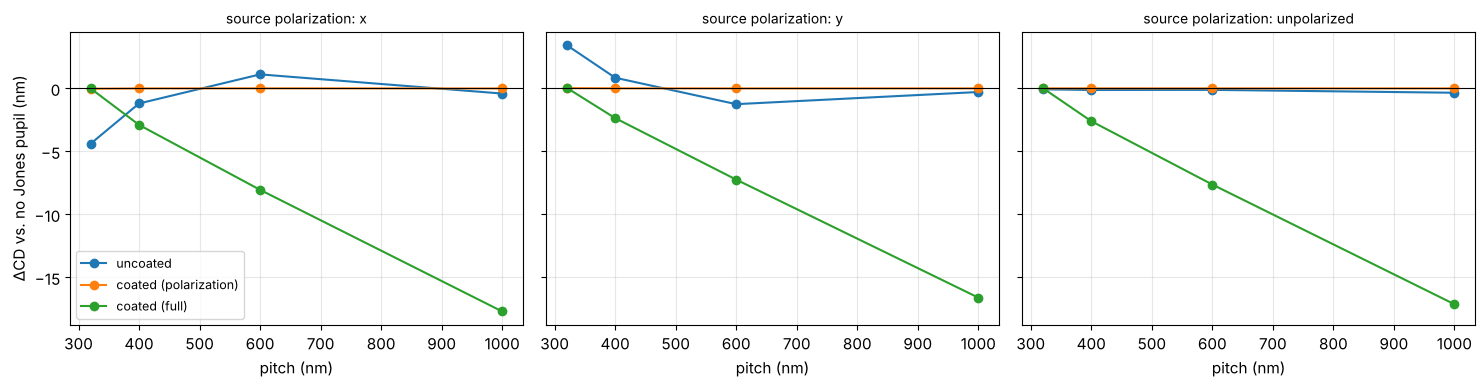

In [8]:
uncoated_pupil = fits["uncoated"][2]  # Pauli-Zernike: the full Jones pupil
coated_full = fits["coated"][2]
coated_polarization = fits["coated"][0]  # retardance and diattenuation only
projector = Projector(uncoated.NA, system.wavelength_nm, magnification=4.0)
pupils = {"no Jones pupil": None, "uncoated": uncoated_pupil,
          "coated (polarization)": coated_polarization, "coated (full)": coated_full}
pitches = [320.0, 400.0, 600.0, 1000.0]
sources = {pol: Illumination.annular(0.85, 0.55, n_samples=21, polarization=pol)
           for pol in ("x", "y", "unpolarized")}

cd = {}
for pol, source in sources.items():
    for name, pupil in pupils.items():
        cd[pol, name] = [LithoSimulation(MaskLayout.lines_spaces(p, p/2), ThinMask.binary(), source,
                                         projector.with_(jones_pupil=pupil)).cd(0.3)
                         for p in pitches]

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, pol in zip(axes, sources):
    for name in list(pupils)[1:]:
        ax.plot(pitches, np.subtract(cd[pol, name], cd[pol, "no Jones pupil"]), "o-", label=name)
    ax.axhline(0, color="k", lw=0.8)
    ax.set_title("source polarization: " + pol, fontsize=10)
    ax.set_xlabel("pitch (nm)"), ax.grid(alpha=0.3)
axes[0].set_ylabel(r"$\Delta$CD vs. no Jones pupil (nm)")
axes[0].legend(fontsize=9)
plt.tight_layout()

The radial diattenuation of the uncoated lens favours the TM ($p$) part of
the orders at the rim of the pupil. For polarized light it changes the
balance between the orders and with it the CD of the densest pitch, with
opposite signs for x and y polarization; for unpolarized light the two
effects nearly cancel. The coating's polarization part is small at NA 0.56.
Its scalar phase, however, is a rotationally symmetric wavefront
(defocus- and spherical-like) and changes the CD of the larger pitches:
for a real lens, it is part of the wavefront budget and is designed out.

## 5. OZP sensitivities at NA 1.35

At immersion NA the angles in the resist are large, so polarization
matters most. As for Zernikes (notebook 27) the response of a CD (or of the
NILS) to an OZP coefficient $c$ is the expansion

$$\Delta\mathrm{CD} = \frac{\partial\,\mathrm{CD}}{\partial c}\,c
 + \frac{1}{2}\frac{\partial^2\mathrm{CD}}{\partial c^2}\,c^2 .$$

Evaluating each OZP at $+c$ and $-c$ separates the two parts: a linear
response flips its sign, a quadratic one does not. The case: 45 nm lines
and spaces, a y-polarized (TE) dipole, ArF water immersion; retardance
$c = 0.02$ waves, diattenuation $c = 0.05$.

without Jones pupil: CD 40.08 nm, NILS 2.936


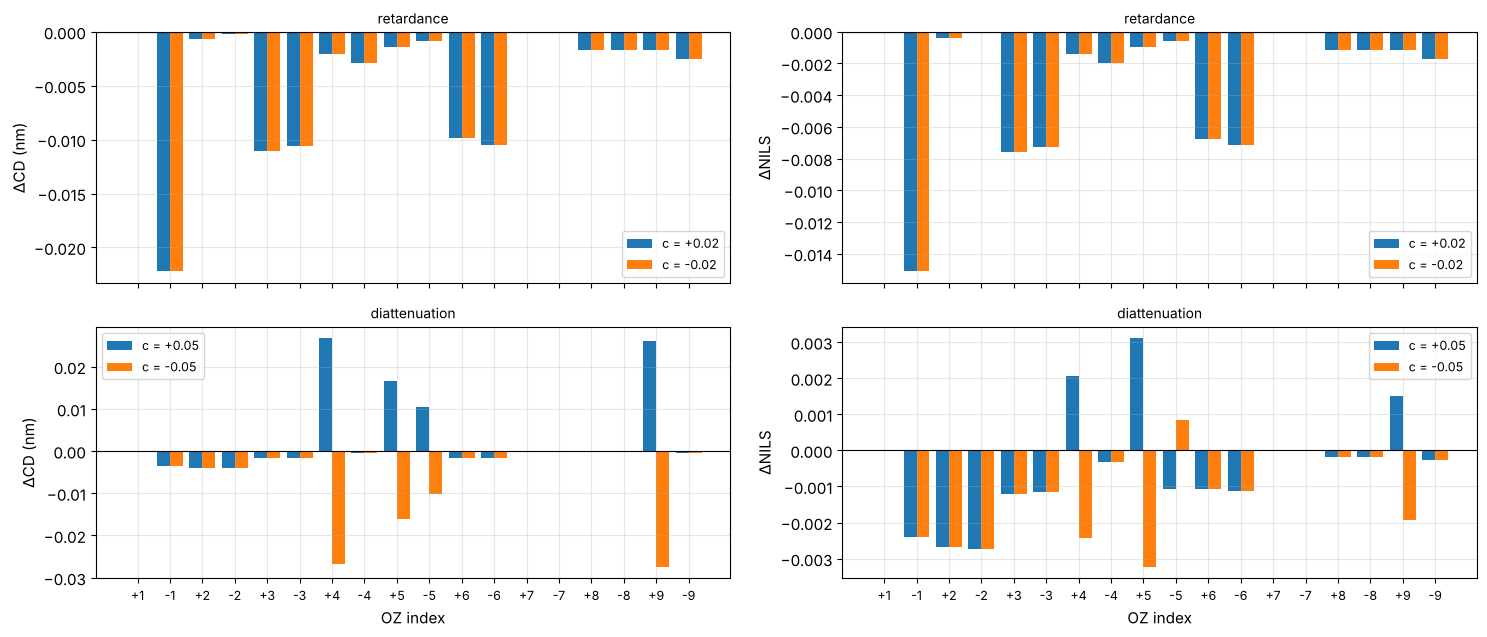

In [9]:
immersion = Projector(1.35, 193.0, n=1.437)
sim = LithoSimulation(MaskLayout.lines_spaces(90.0, 45.0), ThinMask.binary(),
                      Illumination.dipole(0.9, 0.6, n_samples=15, polarization="y"), immersion)
cd0, nils0 = sim.cd(0.3), sim.nils(0.3)
print("without Jones pupil: CD {:.2f} nm, NILS {:.3f}".format(cd0, nils0))

def response(kind, oz, value):
    s = sim.with_(projector=immersion.with_(jones_pupil=jp.PhysicalJonesPupil(**{kind: {oz: value}})))
    return s.cd(0.3) - cd0, s.nils(0.3) - nils0

terms = jp.oz_indices(9)
deltas = {"retardance": 0.02, "diattenuation": 0.05}
results = {(kind, sign): np.array([response(kind, oz, sign*delta) for oz in terms])
           for kind, delta in deltas.items() for sign in (1, -1)}

fig, axes = plt.subplots(2, 2, figsize=(15, 6.5), sharex=True)
x = np.arange(len(terms))
for row, (kind, delta) in zip(axes, deltas.items()):
    for col, metric in enumerate((r"$\Delta$CD (nm)", r"$\Delta$NILS")):
        ax = row[col]
        for sign, offset in ((1, -0.2), (-1, 0.2)):
            ax.bar(x + offset, results[kind, sign][:, col], 0.4, label="c = {:+g}".format(sign*delta))
        ax.axhline(0, color="k", lw=0.8)
        ax.set_ylabel(metric), ax.grid(alpha=0.3)
        ax.set_title(kind, fontsize=10)
        ax.legend(fontsize=9)
for ax in axes[1]:
    ax.set_xticks(x), ax.set_xticklabels(["{:+d}".format(t) for t in terms], fontsize=9)
    ax.set_xlabel("OZ index")
plt.tight_layout()

Two classes of response appear, in line with the sensitivity analysis of
Ruoff and Totzeck:

- **Retardance acts quadratically**: both signs lower the NILS by the same
  amount. The TE light at the poles is an eigenstate of an x/y retarder
  (OZ $+1$ does nothing), but any other orientation converts part of it
  into TM light, which images with less contrast at this NA. OZ $-1$
  (45°) is the most harmful; the other terms matter as far as they rotate
  the axis at the positions of the orders in the pupil.
- **Diattenuation acts linearly** through the terms that change the
  transmission of the zero order relative to the first orders, which lie at
  different positions in the pupil (OZ $+4$, $\pm5$, $+9$ here). A constant
  x/y term (OZ $+1$) only scales the dose, which the normalization to the
  open frame removes.

A tolerance therefore follows from the quadratic coefficient for
retardance and from the linear one for diattenuation. For this two-beam
case the effects are small: even 0.05 waves of the worst retardance term
(OZ $-1$) cost about 0.1 nm of CD and 3 % of the NILS.

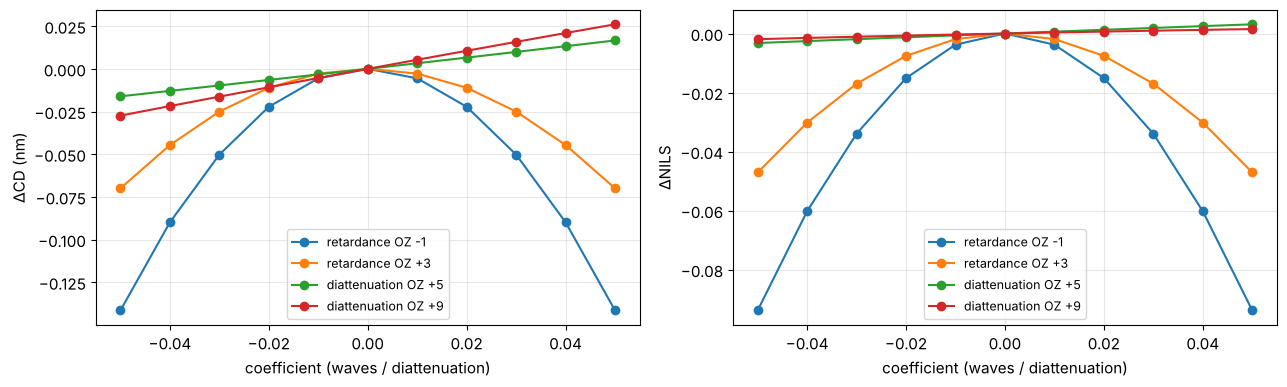

In [10]:
c = np.linspace(-0.05, 0.05, 11)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for kind, oz in (("retardance", -1), ("retardance", 3), ("diattenuation", 5), ("diattenuation", 9)):
    r = np.array([response(kind, oz, v) for v in c])
    for ax, col in zip(axes, r.T):
        ax.plot(c, col, "o-", label="{} OZ {:+d}".format(kind, oz))
for ax, label in zip(axes, (r"$\Delta$CD (nm)", r"$\Delta$NILS")):
    ax.set_xlabel("coefficient (waves / diattenuation)"), ax.set_ylabel(label)
    ax.grid(alpha=0.3), ax.legend(fontsize=9)
plt.tight_layout()

## Summary

- `jones_pupil`: Pauli algebra, orientation Zernike polynomials, the polar
  decomposition and two fitted representations, `PauliZernikePupil` and
  `PhysicalJonesPupil` (OZP retardance and diattenuation). Both plug into
  `Projector(jones_pupil=...)` for Abbe and Hopkins imaging, and they can be
  chained with `@`.
- `lens.lens_jones_pupil()`: polarization ray trace of a lens with Fresnel
  coefficients and optional coatings (`quarter_wave_coating()` or any thin
  film stack per surface).
- The uncoated Caldwell lens is a strong radial diattenuator (OZ $+5$); a
  coating trades diattenuation for retardance and adds a scalar wavefront.
- OZPs sort polarization errors by symmetry like Zernikes sort wavefronts;
  CD responds quadratically to retardance and linearly to diattenuation.
- Not included: stress and intrinsic birefringence of the glass (they would
  enter as additional retarders per ray), and polarization effects of the
  mask and resist interfaces beyond those already in `FilmMask`,
  `RigorousMask` and `WaferStack`.